In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from data_wrangling import read_feature_set
from data_wrangling import create_day_ahead_forecast_split
from quantile_modelling import fit_q50_model, fit_q95_model, calculate_stress_metrics
from probabalistic_validation import pinball_loss, reliability

In [2]:
featured_filtered, candidate_features = read_feature_set()

target = "Balancing_energy_total"

issue_time = pd.Timestamp("2024-06-14 18:00", tz='UTC')

forecast_date = issue_time.normalize() + pd.Timedelta(days=1)
forecast_end = forecast_date + pd.Timedelta(days=1)

In [3]:
train_df, y_train_df, forecast_df = create_day_ahead_forecast_split(
    feature_df=featured_filtered,
    features=candidate_features['q95'],
    issue_time=issue_time,
    target="Balancing_energy_total",
)

y_test = featured_filtered["Balancing_energy_total"].loc[
        (featured_filtered.index >= forecast_date)
        & (featured_filtered.index < forecast_end)
    ]

### XGBoost

In [4]:

forecast_date = issue_time.normalize() + pd.Timedelta(days=1)
forecast_end = forecast_date + pd.Timedelta(days=1)

y_test = featured_filtered["Balancing_energy_total"].loc[
    (featured_filtered.index >= forecast_date)
    & (featured_filtered.index < forecast_end)
]

_, y_xgb_q50 = fit_q50_model(
    df=featured_filtered,
    features=candidate_features,
    issue_time=issue_time,
    model_type="xgb",
)

_, y_xgb_q95 = fit_q95_model(
    df=featured_filtered,
    features=candidate_features,
    issue_time=issue_time,
    model_type="xgb",
)


In [5]:
df_stress = calculate_stress_metrics(q50=y_xgb_q50, q95=y_xgb_q95)

In [6]:

def fanplot(
    mqr_pred,
    response,
    quantile_cols=None,
):

    if quantile_cols is None:
        quantiles = list(map(lambda q: q / 100, range(5, 96, 5)))
        quantile_cols = [f"q{int(q*100)}" for q in quantiles]

    # Create the fan plot
    plt.figure(figsize=(12, 3))

    # Ensure all quantile columns are numeric
    mqr_pred[quantile_cols] = mqr_pred[quantile_cols].apply(pd.to_numeric, errors='coerce')

    # Create fan plot
    plt.figure(figsize=(12, 5))

    for i in range(len(quantile_cols) // 2):
        lower = quantile_cols[i]
        upper = quantile_cols[-(i + 1)]
        plt.fill_between(
            mqr_pred.index, mqr_pred[lower], mqr_pred[upper], alpha=(1/len(quantile_cols)) * (i + 1), label=f'{lower}-{upper}', color='red'
        )

    # Plot median line
    plt.plot(mqr_pred.index, mqr_pred[response], color='black', label='Actual', linewidth=1)

    plt.xlabel("Datetime")
    plt.ylabel(response)
    plt.title(f"Fan Plot of Quantile Predictions Over Time")
    plt.legend(loc='upper right')
    plt.grid(True)
    plt.tight_layout()

In [7]:
d = pd.concat([
    # featured_filtered.loc[:, candidate_features['ex_post']],
    featured_filtered.filter(like=target),
    df_stress
], axis=1).dropna(subset='stress_ratio')

<Figure size 1200x300 with 0 Axes>

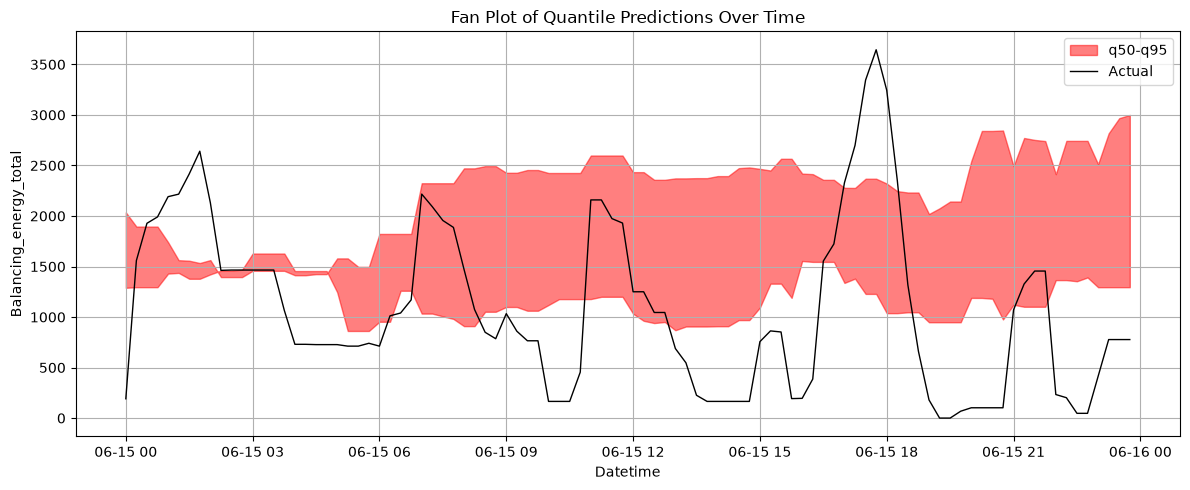

In [8]:
fanplot(
    d,
    target,
    ['q50', 'q95']
)

In [9]:
import pickle


with open('./data/processed/xbg_predictions_25-26.pickle', 'rb') as f: 
    preds = pickle.load(f)

In [10]:
d = pd.concat([
    # featured_filtered.loc[:, candidate_features['ex_post']],
    featured_filtered.filter(like=target),
    preds
], axis=1).dropna(subset='stress_ratio')
d

,Balancing_energy_total,q50,q95,stress_range,stress_ratio
Datetime,,,,,
2025-09-01 00:00:00+00:00,942.3488,917.265137,2422.828857,1505.563721,2.641361
2025-09-01 00:15:00+00:00,1543.4040,874.714111,2422.828857,1548.114746,2.769852
2025-09-01 00:30:00+00:00,1962.8650,874.714111,2417.858398,1543.144287,2.764170
2025-09-01 00:45:00+00:00,1474.8140,874.714111,2407.833496,1533.119385,2.752709
2025-09-01 01:00:00+00:00,983.2080,884.231262,2441.201172,1556.969971,2.760818
...,...,...,...,...,...
2026-08-31 22:45:00+00:00,291.7800,884.848022,2501.589355,1616.741333,2.827140
2026-08-31 23:00:00+00:00,53.7572,601.540161,1988.057373,1386.517212,3.304945
2026-08-31 23:15:00+00:00,145.1060,615.305725,2010.101807,1394.796143,3.266834


<Figure size 1200x300 with 0 Axes>

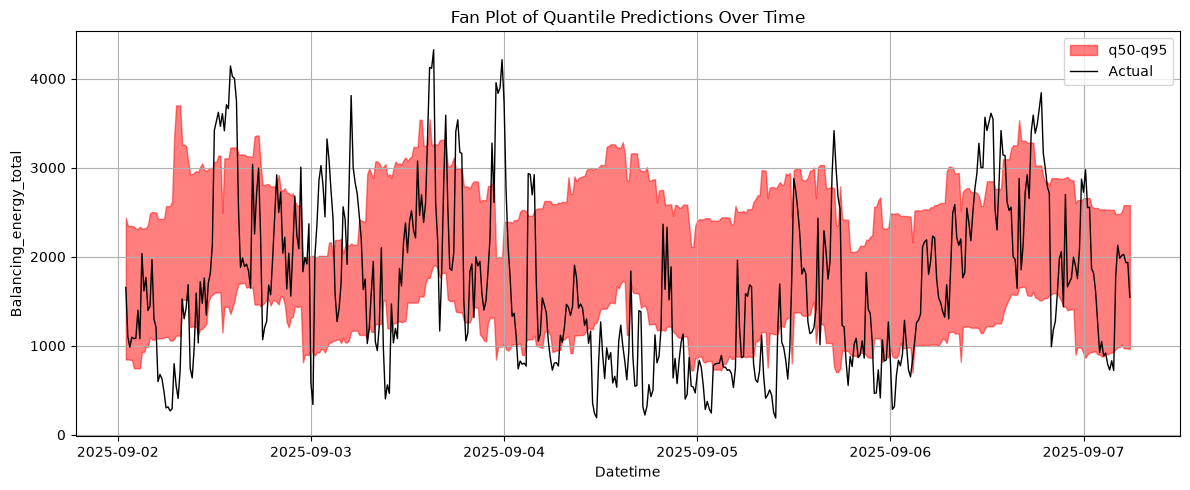

In [11]:
offset = int(1e2)
fanplot(
    d.iloc[offset:offset+500],
    target,
    ['q50', 'q95']
)

In [12]:
print(pd.concat([
    # featured_filtered.loc[:, candidate_features['ex_post']],
    featured_filtered.filter(like=target),
    df_stress
], axis=1).dropna(subset='stress_ratio').to_markdown())

| Datetime                  |   Balancing_energy_total |      q50 |     q95 |   stress_range |   stress_ratio |
|:--------------------------|-------------------------:|---------:|--------:|---------------:|---------------:|
| 2024-06-15 00:00:00+00:00 |                   191    | 1289.43  | 2035.82 |       746.39   |       1.57885  |
| 2024-06-15 00:15:00+00:00 |                  1559    | 1295.2   | 1895.06 |       599.864  |       1.46315  |
| 2024-06-15 00:30:00+00:00 |                  1927.68 | 1295.2   | 1895.06 |       599.864  |       1.46315  |
| 2024-06-15 00:45:00+00:00 |                  1990.68 | 1295.2   | 1895.06 |       599.864  |       1.46315  |
| 2024-06-15 01:00:00+00:00 |                  2191    | 1429.72  | 1740.45 |       310.725  |       1.21733  |
| 2024-06-15 01:15:00+00:00 |                  2216    | 1436.84  | 1562.49 |       125.658  |       1.08745  |
| 2024-06-15 01:30:00+00:00 |                  2416    | 1378.64  | 1557.37 |       178.73   |       1.1